# 31_0 v2: Event Study Assumption Checks (Deep Dive)

This is a revised, deeper version of `31_0_event_study_assumptions.ipynb`. It reuses the
cached prices and the retained event sample produced by `31_event_study.ipynb` (no network
calls, no re-detection of peaks) but replaces the original's six single-metric checks with
a shared, reusable market-model engine (`src/event_study_utils.py`) and seven more detailed
checks:

1. Timing (calendar-span buckets, clustered regression, trading-day-anchoring sensitivity)
2. Pre-trend and drift (common-sample CAAR with clustered bands, window-specific tests)
3. Magnitude and power (null benchmarks, minimum-detectable-effect table, planted-effect
   simulation)
4. Normality (kurtosis/skew/Q-Q, multiple one-sided tests side by side, bootstrap, robust means)
5. Autocorrelation (region split, lagged-market test, flagged-event exclusion re-run)
6. Confounding (estimation-window overlap, +/-10-trading-day flag, clean-vs-contaminated test)
7. Tail and data-quality scan (extreme CARs, unit-flip/split check, sensitivity re-runs)

All new outputs are written to `results/phase_iv/` with the `assump_v2_` prefix. Nothing in
`results/` without that prefix, and neither `31_event_study.ipynb` nor the original
`31_0_event_study_assumptions.ipynb`, is read or modified by this notebook.

A regression guard runs immediately after data loading: the shared engine must reproduce
`event_study_results_v3.parquet`'s `car`/`scar` for all 1,463 events to within 1e-9 before
anything else runs.

**Note on `ar_day_i` columns in `event_study_results_v3.parquet`:** the index `i` is a
*position* within the 7-day event window (-1..+5), not the literal day offset: `ar_day_0` is
offset -1, `ar_day_1` is offset 0, ..., `ar_day_6` is offset +5. This notebook's own engine
output (`event_window_stats(...)['ar']`) is indexed by actual offset instead, to avoid
repeating that ambiguity in new code.

## Step 0 — Setup

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import mstats
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')

# Repo root is the parent of this notebook's cwd (notebooks/); add it to sys.path so the
# shared engine module resolves regardless of the (broken) editable pip install.
sys.path.insert(0, str(Path('..').resolve()))
from src.event_study_utils import (
    event_window_stats, bmp_test, cluster_robust_mean_test_fast,
    get_trading_day_offset, estimate_market_model,
    ESTIMATION_START, ESTIMATION_END, MIN_EST_OBS,
)

OUTPUT_DIR = Path('results/phase_iv')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RNG_SEED = 42
EVENT_WINDOW = (-1, 5)

T_START = time.time()
print(f'Estimation window: [{ESTIMATION_START}, {ESTIMATION_END}]   MIN_EST_OBS={MIN_EST_OBS}')

Estimation window: [-210, -11]   MIN_EST_OBS=50


In [2]:
# Exchange suffix map -- copied verbatim from 31_event_study.ipynb (Step 2) so yf_ticker
# can be reconstructed; not stored in the saved event_study_results_v3.parquet.
TICKER_SUFFIX_MAP = {
    # Germany (Frankfurt)
    'SIE':  'SIE.DE',  'BAYN': 'BAYN.DE', 'LHA':  'LHA.DE',
    'BAS':  'BAS.DE',  'ADS':  'ADS.DE',  'VOW3': 'VOW3.DE', 'PAH3': 'PAH3.DE',
    # Switzerland
    'ZURN': 'ZURN.SW', 'NESN': 'NESN.SW', 'NOVN': 'NOVN.SW',
    # UK (London)
    'HSBA': 'HSBA.L',  'LLOY': 'LLOY.L',  'GLEN': 'GLEN.L',
    'RR.':  'RR.L',    'BA.':  'BA.L',     'SVT':  'SVT.L',
    'ULVR': 'ULVR.L',  'UU.':  'UU.L',     'NG.':  'NG.L',
    'AV.':  'AV.L',    'LSEG': 'LSEG.L',   'STAN': 'STAN.L',
    # France (Paris)
    'RNO':  'RNO.PA',  'PUB':  'PUB.PA',   'AC':   'AC.PA',
    'ML':   'ML.PA',   'ALO':  'ALO.PA',   'VIE':  'VIE.PA',
    # Netherlands (Amsterdam)
    'PHIA': 'PHIA.AS', 'UMG':  'UMG.AS',
    # Sweden (Stockholm) -- B-share tickers use hyphen on yfinance
    'SAAB B':  'SAAB-B.ST', 'VOLV B':   'VOLV-B.ST', 'ERIC B': 'ERIC-B.ST',
    # Denmark (Copenhagen)
    'PNDORA':  'PNDORA.CO', 'MAERSK B': 'MAERSK-B.CO', 'VWS': 'VWS.CO',
    # Finland
    'NOKIA': 'NOKIA.HE',
    # Spain
    'CLNX':  'CLNX.MC',
    # Belgium
    'ABI':   'ABI.BR',
    # Japan (Tokyo)
    '7203': '7203.T', '8604': '8604.T', '6758': '6758.T',
    '7751': '7751.T', '7733': '7733.T', '7267': '7267.T',
    '7974': '7974.T', '9201': '9201.T', '8306': '8306.T',
    '7201': '7201.T', '9434': '9434.T', '6501': '6501.T',
    '7269': '7269.T', '8316': '8316.T', '2587': '2587.T',
    # Hong Kong
    '823':  '0823.HK',
    # Australia (ASX)
    'MQG': 'MQG.AX', 'QAN': 'QAN.AX', 'WOW': 'WOW.AX', 'WBC': 'WBC.AX',
    # Canada (Toronto)
    'FFH': 'FFH.TO',
    # US -- special case (B-share uses hyphen)
    'BRKB': 'BRK-B',
}

## Step 1 — Load data

Same four inputs as the original notebook, plus the MSCI sector/region merge that
`31_event_study.ipynb` does in its own Step 8 (needed here for check 5's region split and
check 3b's sector-level MDE table).

In [3]:
PRICE_CACHE = OUTPUT_DIR / 'price_cache_v4_acwi.parquet'
EVENT_STUDY_RESULTS = OUTPUT_DIR / 'event_study_results_v3.parquet'
PEAKS_PATH = Path('results/phase_iii/all_peaks_loose_threshold.parquet')
MSCI_PATH = Path('data/00_raw/msci_world.csv')

prices = pd.read_parquet(PRICE_CACHE)
prices.index = pd.to_datetime(prices.index)
returns = np.log(prices / prices.shift(1)).dropna(how='all')

event_df = pd.read_parquet(EVENT_STUDY_RESULTS)
event_df['event_date'] = pd.to_datetime(event_df['event_date'])
event_df['yf_ticker'] = event_df['ticker'].map(TICKER_SUFFIX_MAP).fillna(event_df['ticker'])

all_peaks = pd.read_parquet(PEAKS_PATH)
all_peaks['start_date'] = pd.to_datetime(all_peaks['start_date'])
all_peaks['end_date'] = pd.to_datetime(all_peaks['end_date'])
all_peaks['yf_ticker'] = all_peaks['ticker'].map(TICKER_SUFFIX_MAP).fillna(all_peaks['ticker'])

msci_df = pd.read_csv(MSCI_PATH, sep=';', skiprows=7)
msci_df = msci_df.drop_duplicates(subset='Ticker', keep='first')
sector_col = next((c for c in msci_df.columns if 'sector' in c.lower() or 'gics' in c.lower()), None)
print(f'MSCI sector column identified: {sector_col}')

# Merge on the ORIGINAL ticker (not yf_ticker) -- msci_world.csv uses unsuffixed tickers,
# same convention as 31_event_study.ipynb Step 8.
event_df = event_df.merge(
    msci_df[['Ticker', 'Location', sector_col]].rename(
        columns={'Ticker': 'ticker_msci', 'Location': 'region', sector_col: 'sector'}),
    left_on='ticker', right_on='ticker_msci', how='left'
).drop(columns=['ticker_msci'])

mkt_rets = returns['ACWI'].dropna()
trading_cal = mkt_rets.index

firm_rets_cache = {
    tkr: (returns[tkr].dropna() if tkr in returns.columns else None)
    for tkr in event_df['yf_ticker'].unique()
}

print(f'Prices           : {prices.shape}')
print(f'Retained events   : {len(event_df):,} (from {event_df["ticker"].nunique()} firms)')
print(f'Full peak catalog : {len(all_peaks):,}')
print(f'Region matched    : {event_df["region"].notna().sum():,} / {len(event_df):,}')
print(f'Sector matched    : {event_df["sector"].notna().sum():,} / {len(event_df):,}')

MSCI sector column identified: Sector
Prices           : (4686, 239)
Retained events   : 1,463 (from 210 firms)
Full peak catalog : 1,774
Region matched    : 1,463 / 1,463
Sector matched    : 1,463 / 1,463


## Step 2 — REGRESSION GUARD

Before trusting anything downstream, the shared engine (`event_window_stats`, anchor=`'ffill'`,
window `(-1,5)`) must reproduce `event_study_results_v3.parquet`'s stored `car`/`scar` for
every one of the 1,463 retained events to within 1e-9. If it doesn't, the engine disagrees with
the main event-study notebook's own arithmetic and nothing below this cell is trustworthy --
the notebook halts rather than continuing silently.

In [4]:
max_diff_car = 0.0
max_diff_scar = 0.0
n_mismatch = 0
n_not_computable = 0

for _, ev in event_df.iterrows():
    firm_rets = firm_rets_cache.get(ev['yf_ticker'])
    if firm_rets is None:
        n_not_computable += 1
        continue
    res = event_window_stats(firm_rets, mkt_rets, trading_cal, ev['event_date'], -1, 5, anchor='ffill')
    if res is None:
        n_not_computable += 1
        continue
    d_car = abs(res['car'] - ev['car'])
    d_scar = abs(res['scar'] - ev['scar'])
    max_diff_car = max(max_diff_car, d_car)
    max_diff_scar = max(max_diff_scar, d_scar)
    if d_car > 1e-9 or d_scar > 1e-9:
        n_mismatch += 1

guard_pass = (n_not_computable == 0 and n_mismatch == 0)
print('=' * 70)
print('REGRESSION GUARD: anchor=ffill, window=(-1,5), all 1,463 events')
print('=' * 70)
print(f'  Not computable      : {n_not_computable}')
print(f'  Mismatches (>1e-9)  : {n_mismatch}')
print(f'  Max abs diff (car)  : {max_diff_car:.3e}')
print(f'  Max abs diff (scar) : {max_diff_scar:.3e}')
print(f'  RESULT: {"PASS" if guard_pass else "FAIL"}')

if not guard_pass:
    raise AssertionError(
        'Regression guard FAILED: the shared engine does not reproduce '
        'event_study_results_v3.parquet to within 1e-9. Halting -- see message above for the '
        'measured max differences. Do not trust any check below until this is fixed.'
    )

REGRESSION GUARD: anchor=ffill, window=(-1,5), all 1,463 events
  Not computable      : 0
  Mismatches (>1e-9)  : 0
  Max abs diff (car)  : 0.000e+00
  Max abs diff (scar) : 0.000e+00
  RESULT: PASS


In [5]:
display(Markdown(
    f"**Guard result:** engine reproduces all {len(event_df):,} events' `car` and `scar` to "
    f"within **{max(max_diff_car, max_diff_scar):.1e}** (tolerance 1e-9). "
    f"{'No events were non-computable.' if n_not_computable == 0 else f'{n_not_computable} events were not computable by the engine -- investigate before proceeding.'}"
))

**Guard result:** engine reproduces all 1,463 events' `car` and `scar` to within **0.0e+00** (tolerance 1e-9). No events were non-computable.

## Step 3 — Per-event residual series cache

Checks 2 (pre-trend/drift bands), 4 (normality) and 5 (autocorrelation) all need each
retained event's own estimation-window ([-210,-11]) residual series, not just the summary
`alpha`/`beta`/`resid_std` already stored in the parquet. Refit once here and reuse.

In [6]:
residual_series = {}   # peak_id -> estimation-window residual Series (datetime-indexed)
refit_params = {}       # peak_id -> (alpha, beta)

for _, ev in event_df.iterrows():
    firm_rets = firm_rets_cache.get(ev['yf_ticker'])
    if firm_rets is None:
        continue
    ref_date = ev['event_date']
    est_s = get_trading_day_offset(trading_cal, ref_date, ESTIMATION_START, anchor='ffill')
    est_e = get_trading_day_offset(trading_cal, ref_date, ESTIMATION_END, anchor='ffill')
    if est_s is None or est_e is None:
        continue
    model = estimate_market_model(firm_rets, mkt_rets, est_s, est_e)
    if model is None:
        continue
    alpha, beta, resid_std, n_est, x_bar, sxx = model
    mask = (firm_rets.index >= est_s) & (firm_rets.index <= est_e)
    y = firm_rets.loc[mask].dropna()
    x = mkt_rets.reindex(y.index).dropna()
    y, x = y.align(x, join='inner')
    resid = y - (alpha + beta * x)
    residual_series[ev['peak_id']] = resid
    refit_params[ev['peak_id']] = (alpha, beta)

print(f'Residual series recovered for {len(residual_series):,} / {len(event_df):,} events')

Residual series recovered for 1,463 / 1,463 events


## Check 1 — Timing

An event study needs a clear, identifiable event date. Our peaks are detected spans with a
`start_date` and `end_date` (the end date of the *elevated-article-day* window, not the same
as `duration_days` -- see the merge below). `calendar_span_days = end_date - start_date` is
the actual calendar fuzziness of the nominal event date: a 1-day span pins the date tightly,
a 300-day span means "somewhere in this stretch of a year" is doing a lot of work.

Buckets: `<=3`, `4-30`, `>30` calendar days. Per bucket: n, mean CAR[-1,+5], mean CAR[0,+5],
mean AR on days -1/0/+1, mean SCAR, BMP t, firm-clustered t -- plus a clustered OLS of CAR on
bucket dummies, and a check of how many events' `start_date` falls on a non-trading day (and
whether anchoring to the previous vs. next trading day changes day-0 AR / CAR for those).

In [7]:
event_df = event_df.merge(
    all_peaks[['peak_id', 'end_date', 'start_date']].rename(columns={'start_date': 'start_date_peaks'}),
    on='peak_id', how='left')
assert (event_df['event_date'] == event_df['start_date_peaks']).all(), \
    'event_date should equal all_peaks.start_date for every retained event'
event_df['calendar_span_days'] = (event_df['end_date'] - event_df['event_date']).dt.days

def _bucket(d):
    if d <= 3:
        return '<=3'
    elif d <= 30:
        return '4-30'
    else:
        return '>30'

event_df['timing_bucket'] = event_df['calendar_span_days'].apply(_bucket)
print(event_df['timing_bucket'].value_counts())

timing_bucket
>30     618
4-30    608
<=3     237
Name: count, dtype: int64


In [8]:
timing_rows = []
for b in ['<=3', '4-30', '>30']:
    sub = event_df[event_df['timing_bucket'] == b]
    bmp_t, bmp_p = bmp_test(sub['scar'].values)
    clu = cluster_robust_mean_test_fast(sub['car'].values, sub['ticker'].values)
    timing_rows.append(dict(
        bucket=b, n=len(sub),
        mean_car_m1_p5=sub['car'].mean(), mean_car_0_p5=sub['car_post'].mean(),
        mean_ar_m1=sub['ar_day_0'].mean(), mean_ar_0=sub['ar_day_1'].mean(), mean_ar_p1=sub['ar_day_2'].mean(),
        mean_scar=sub['scar'].mean(), bmp_t=bmp_t, bmp_p=bmp_p,
        clustered_t=clu['t_stat'], clustered_p=clu['p_value'], n_clusters=clu['n_clusters'],
    ))
timing_df = pd.DataFrame(timing_rows)
print(timing_df.to_string(index=False))
timing_df.to_csv(OUTPUT_DIR / 'assump_v2_timing_buckets.csv', index=False)

bucket   n  mean_car_m1_p5  mean_car_0_p5  mean_ar_m1  mean_ar_0  mean_ar_p1  mean_scar     bmp_t    bmp_p  clustered_t  clustered_p  n_clusters
   <=3 237       -0.010113      -0.008499   -0.001614  -0.000114   -0.003378  -0.189545 -1.826881 0.034490    -2.062360     0.022194          51
  4-30 608       -0.001516      -0.001477   -0.000038  -0.000323    0.000671  -0.097169 -1.950091 0.025813    -0.524596     0.300570          92
   >30 618       -0.005586      -0.004934   -0.000652  -0.003276   -0.000347  -0.114319 -2.722969 0.003326    -3.192319     0.000819         202


                            Coef.  Std.Err.         z     P>|z|    [0.025  \
Intercept               -0.001516  0.002882 -0.525853  0.598990 -0.007164   
C(timing_bucket)[T.<=3] -0.008597  0.006017 -1.428954  0.153017 -0.020389   
C(timing_bucket)[T.>30] -0.004071  0.003596 -1.132056  0.257611 -0.011119   

                           0.975]  
Intercept                0.004133  
C(timing_bucket)[T.<=3]  0.003195  
C(timing_bucket)[T.>30]  0.002977  


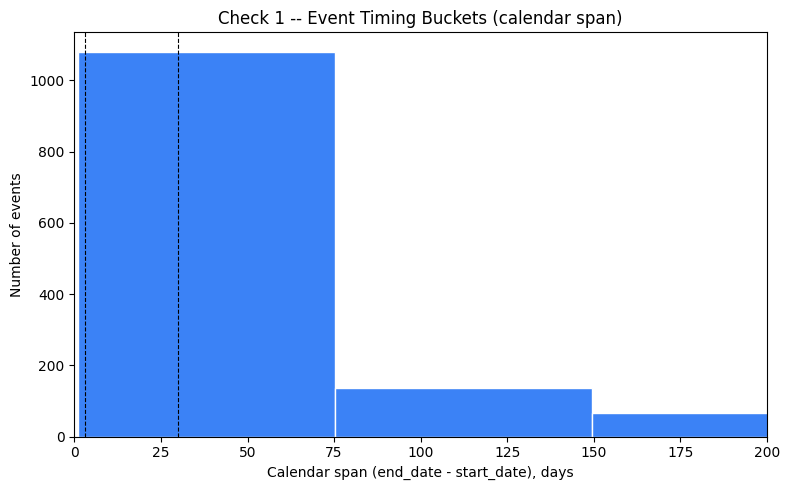

In [9]:
timing_reg = smf.ols('car ~ C(timing_bucket)', data=event_df).fit(
    cov_type='cluster', cov_kwds={'groups': event_df['ticker']})
print(timing_reg.summary2().tables[1])
with open(OUTPUT_DIR / 'assump_v2_timing_regression.txt', 'w') as f:
    f.write(timing_reg.summary().as_text())

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(event_df['calendar_span_days'], bins=50, color='#3b82f6', edgecolor='white')
ax.axvline(3, color='black', lw=0.8, ls='--')
ax.axvline(30, color='black', lw=0.8, ls='--')
ax.set_xlabel('Calendar span (end_date - start_date), days')
ax.set_ylabel('Number of events')
ax.set_title('Check 1 -- Event Timing Buckets (calendar span)')
ax.set_xlim(0, 200)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump_v2_timing_buckets.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
is_trading = event_df['event_date'].isin(trading_cal)
non_trading = event_df[~is_trading]
n_changed_ar0 = 0
n_changed_car = 0
n_comparable = 0
for _, ev in non_trading.iterrows():
    firm_rets = firm_rets_cache.get(ev['yf_ticker'])
    if firm_rets is None:
        continue
    res_ff = event_window_stats(firm_rets, mkt_rets, trading_cal, ev['event_date'], -1, 5, anchor='ffill')
    res_bf = event_window_stats(firm_rets, mkt_rets, trading_cal, ev['event_date'], -1, 5, anchor='bfill')
    if res_ff is None or res_bf is None:
        continue
    n_comparable += 1
    ar0_ff = res_ff['ar'][res_ff['offsets'].index(0)]
    ar0_bf = res_bf['ar'][res_bf['offsets'].index(0)]
    if not np.isclose(ar0_ff, ar0_bf, atol=1e-12):
        n_changed_ar0 += 1
    if not np.isclose(res_ff['car'], res_bf['car'], atol=1e-12):
        n_changed_car += 1

print(f'Non-trading-day start_date events : {len(non_trading)} / {len(event_df)} ({len(non_trading)/len(event_df)*100:.1f}%)')
print(f'Comparable under both anchors      : {n_comparable}')
print(f'Changed day-0 AR (bfill vs ffill)  : {n_changed_ar0} / {n_comparable}')
print(f'Changed CAR (bfill vs ffill)       : {n_changed_car} / {n_comparable}')

anchor_sensitivity = pd.DataFrame([dict(
    n_non_trading_start=len(non_trading), pct_non_trading_start=len(non_trading)/len(event_df)*100,
    n_comparable=n_comparable, n_changed_day0_ar=n_changed_ar0, n_changed_car=n_changed_car,
)])
anchor_sensitivity.to_csv(OUTPUT_DIR / 'assump_v2_anchor_sensitivity.csv', index=False)

Non-trading-day start_date events : 222 / 1463 (15.2%)
Comparable under both anchors      : 220
Changed day-0 AR (bfill vs ffill)  : 220 / 220
Changed CAR (bfill vs ffill)       : 220 / 220


**Interpretation:** calendar span splits events into {'>30': 618, '4-30': 608, '<=3': 237}. The clustered-OLS bucket-dummy regression's F-test / coefficient p-values above show whether CAR differs systematically by timing fuzziness. Separately, 222 of 1,463 retained events (15.2%) have a `start_date` that is not itself a trading day; of the 220 where both anchorings are computable, **220** (100%) have a different day-0 abnormal return and **220** (100%) a different CAR[-1,+5] depending on whether the nominal date is anchored to the previous or next trading day -- i.e. essentially all of them shift under re-anchoring, since a different trading day enters the sum entirely.

## Check 2 — Pre-trend and drift

On the common sample where the full [-10,+20] window is observable, compute mean AR by day
and the cumulative average abnormal return (CAAR) with firm-clustered 95% bands. Then test
CAR[-10,-2] (pre-trend: should be ~0 under market efficiency / no leakage) and CAR[+6,+20]
(drift: should be ~0 if the [-1,+5] window captures the full reaction) using window-specific
SCAR (BMP t) and a firm-clustered test, each computed via a fresh call to the shared engine
for that specific window -- not derived by slicing the [-10,+20] AR array, since SCAR's
forecast-variance factor is window-specific.

In [12]:
common_rows = []
n_lost_common = 0
for _, ev in event_df.iterrows():
    firm_rets = firm_rets_cache.get(ev['yf_ticker'])
    if firm_rets is None:
        n_lost_common += 1
        continue
    res = event_window_stats(firm_rets, mkt_rets, trading_cal, ev['event_date'], -10, 20, anchor='ffill')
    if res is None:
        n_lost_common += 1
        continue
    common_rows.append(dict(peak_id=ev['peak_id'], ticker=ev['ticker'], ar=res['ar']))

offsets_full = list(range(-10, 21))
ar_matrix = np.array([r['ar'] for r in common_rows])
tickers_full = np.array([r['ticker'] for r in common_rows])
n_common = len(common_rows)
print(f'Common sample with full [-10,+20] window available: n={n_common}  (lost {n_lost_common} of {len(event_df)})')

Common sample with full [-10,+20] window available: n=1348  (lost 115 of 1463)


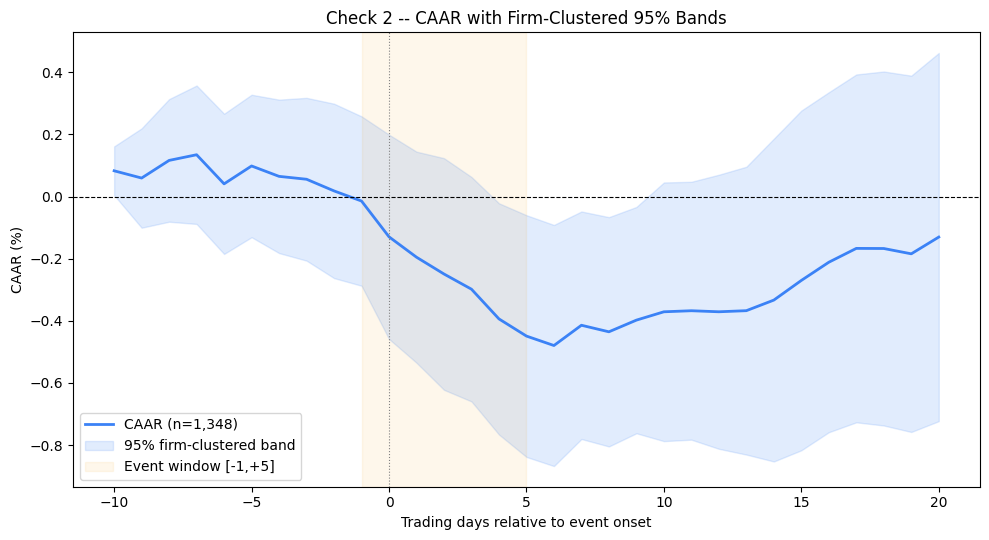

In [13]:
mean_ar_by_day = ar_matrix.mean(axis=0)
caar = np.cumsum(mean_ar_by_day)
cum_ar_per_event = np.cumsum(ar_matrix, axis=1)
caar_se = np.array([
    cluster_robust_mean_test_fast(cum_ar_per_event[:, t], tickers_full)['se']
    for t in range(cum_ar_per_event.shape[1])
])

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(offsets_full, caar * 100, color='#3b82f6', lw=2, label=f'CAAR (n={n_common:,})')
ax.fill_between(offsets_full, (caar - 1.96 * caar_se) * 100, (caar + 1.96 * caar_se) * 100,
                 color='#3b82f6', alpha=0.15, label='95% firm-clustered band')
ax.axhline(0, color='black', lw=0.8, ls='--')
ax.axvspan(-1, 5, color='#f59e0b', alpha=0.08, label='Event window [-1,+5]')
ax.axvline(0, color='grey', lw=0.8, ls=':')
ax.set_xlabel('Trading days relative to event onset')
ax.set_ylabel('CAAR (%)')
ax.set_title('Check 2 -- CAAR with Firm-Clustered 95% Bands')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump_v2_pretrend_drift.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
pretrend_rows, drift_rows = [], []
for _, ev in event_df.iterrows():
    firm_rets = firm_rets_cache.get(ev['yf_ticker'])
    if firm_rets is None:
        continue
    res_pre = event_window_stats(firm_rets, mkt_rets, trading_cal, ev['event_date'], -10, -2, anchor='ffill')
    res_drift = event_window_stats(firm_rets, mkt_rets, trading_cal, ev['event_date'], 6, 20, anchor='ffill')
    if res_pre is not None:
        pretrend_rows.append(dict(peak_id=ev['peak_id'], ticker=ev['ticker'], car=res_pre['car'], scar=res_pre['scar']))
    if res_drift is not None:
        drift_rows.append(dict(peak_id=ev['peak_id'], ticker=ev['ticker'], car=res_drift['car'], scar=res_drift['scar']))

pretrend_df2 = pd.DataFrame(pretrend_rows)
drift_df2 = pd.DataFrame(drift_rows)

bmp_t_pre, bmp_p_pre = bmp_test(pretrend_df2['scar'].values)
bmp_t_drift, bmp_p_drift = bmp_test(drift_df2['scar'].values)
clu_pre = cluster_robust_mean_test_fast(pretrend_df2['car'].values, pretrend_df2['ticker'].values)
clu_drift = cluster_robust_mean_test_fast(drift_df2['car'].values, drift_df2['ticker'].values)

print(f'Pre-trend CAR[-10,-2]: n={len(pretrend_df2)}, mean={pretrend_df2["car"].mean()*100:+.3f}%, '
      f'BMP t={bmp_t_pre:+.3f} p={bmp_p_pre:.4f}, clustered t={clu_pre["t_stat"]:+.3f} p={clu_pre["p_value"]:.4f}')
print(f'Drift CAR[+6,+20]   : n={len(drift_df2)}, mean={drift_df2["car"].mean()*100:+.3f}%, '
      f'BMP t={bmp_t_drift:+.3f} p={bmp_p_drift:.4f}, clustered t={clu_drift["t_stat"]:+.3f} p={clu_drift["p_value"]:.4f}')

pretrend_drift_summary = pd.DataFrame([
    dict(window='pretrend[-10,-2]', n=len(pretrend_df2), mean_car=pretrend_df2['car'].mean(),
         bmp_t=bmp_t_pre, bmp_p=bmp_p_pre, clustered_t=clu_pre['t_stat'], clustered_p=clu_pre['p_value']),
    dict(window='drift[+6,+20]', n=len(drift_df2), mean_car=drift_df2['car'].mean(),
         bmp_t=bmp_t_drift, bmp_p=bmp_p_drift, clustered_t=clu_drift['t_stat'], clustered_p=clu_drift['p_value']),
])
pretrend_drift_summary.to_csv(OUTPUT_DIR / 'assump_v2_pretrend_drift.csv', index=False)

Pre-trend CAR[-10,-2]: n=1412, mean=-0.053%, BMP t=+0.010 p=0.5038, clustered t=-0.359 p=0.3601
Drift CAR[+6,+20]   : n=1378, mean=+0.268%, BMP t=+1.127 p=0.8700, clustered t=+1.353 p=0.9113


**Interpretation:** on the common n=1,348 sample, mean pre-trend CAR[-10,-2] is **-0.053%** (BMP p=0.504, clustered p=0.360) -- not distinguishable from zero at 5%, consistent with no detectable anticipation before the event window. Mean post-window drift CAR[+6,+20] is **+0.268%** (BMP p=0.870, clustered p=0.911) -- not distinguishable from zero, consistent with the [-1,+5] window capturing the bulk of the reaction.

## Check 3 — Magnitude and power

**(a)** Replace the single "mean |scar|" line from the original notebook with explicit
observed-vs-null benchmarks: `E|Z|=0.798`, `P(|Z|>1)=0.317`, `P(|Z|>1.96)=0.05` under a
standard-normal null, and `SD(SCAR)` vs. the theoretical 1.

**(b)** Minimum detectable effect, `MDE = (1.645+0.842)*SD(CAR)/sqrt(n)`, for the full sample
and for every emotion/category/sector subgroup with n>=20, next to the observed mean CAR.

**(c)** A planted-effect (placebo) power simulation: build a pool of pseudo-events (firm+year
matched, excluding +/-10 trading days around any catalog peak for that firm), then for each
(n, delta) cell draw B=1000 samples, add delta to CAR/SCAR, and test with BMP, a firm-clustered
test, and Wilcoxon.

In [16]:
scar_all = event_df['scar'].dropna()
obs_mean_abs_z = scar_all.abs().mean()
obs_p_gt1 = (scar_all.abs() > 1).mean()
obs_p_gt196 = (scar_all.abs() > 1.96).mean()
obs_sd_scar = scar_all.std()

magnitude_benchmarks = pd.DataFrame([
    dict(metric='E|Z|', observed=obs_mean_abs_z, null=0.798),
    dict(metric='P(|Z|>1)', observed=obs_p_gt1, null=0.317),
    dict(metric='P(|Z|>1.96)', observed=obs_p_gt196, null=0.05),
    dict(metric='SD(SCAR)', observed=obs_sd_scar, null=1.0),
])
print(magnitude_benchmarks.to_string(index=False))
magnitude_benchmarks.to_csv(OUTPUT_DIR / 'assump_v2_magnitude_benchmarks.csv', index=False)

     metric  observed  null
       E|Z|  0.832909 0.798
   P(|Z|>1)  0.280246 0.317
P(|Z|>1.96)  0.077239 0.050
   SD(SCAR)  1.224455 1.000


**Interpretation:** observed E|Z|=0.833 vs. null 0.798, P(|Z|>1)=0.280 vs. null 0.317, P(|Z|>1.96)=0.077 vs. null 0.05, SD(SCAR)=1.224 vs. 1. SCAR is more spread out than the unit-normal benchmark (SD well above 1) and the tail probability at 1.96 exceeds the 5% nominal rate, consistent with event-induced variance / cross-sectional heteroskedasticity that the BMP standardization only partially removes.

In [18]:
def _mde(sd, n):
    return (1.645 + 0.842) * sd / np.sqrt(n)

mde_rows = [dict(group='ALL', n=len(event_df), sd_car=event_df['car'].std(),
                  mde=_mde(event_df['car'].std(), len(event_df)), observed_mean_car=event_df['car'].mean())]
for emo, sub in event_df.groupby('dominant_emotion'):
    if len(sub) >= 20:
        mde_rows.append(dict(group=f'emotion:{emo}', n=len(sub), sd_car=sub['car'].std(),
                              mde=_mde(sub['car'].std(), len(sub)), observed_mean_car=sub['car'].mean()))
for cat, sub in event_df.groupby('primary_category'):
    if len(sub) >= 20:
        mde_rows.append(dict(group=f'category:{cat}', n=len(sub), sd_car=sub['car'].std(),
                              mde=_mde(sub['car'].std(), len(sub)), observed_mean_car=sub['car'].mean()))
for sec, sub in event_df.groupby('sector'):
    if len(sub) >= 20:
        mde_rows.append(dict(group=f'sector:{sec}', n=len(sub), sd_car=sub['car'].std(),
                              mde=_mde(sub['car'].std(), len(sub)), observed_mean_car=sub['car'].mean()))

mde_df = pd.DataFrame(mde_rows)
mde_df['mde_exceeded'] = mde_df['observed_mean_car'].abs() > mde_df['mde']
print(mde_df.to_string(index=False))
mde_df.to_csv(OUTPUT_DIR / 'assump_v2_mde_table.csv', index=False)

                        group    n   sd_car      mde  observed_mean_car  mde_exceeded
                          ALL 1463 0.057539 0.003741          -0.004628          True
                emotion:anger  366 0.047584 0.006186          -0.001110         False
              emotion:disgust  340 0.043152 0.005820          -0.003058         False
                 emotion:fear  406 0.073415 0.009061          -0.009712          True
              emotion:sadness  351 0.058155 0.007720          -0.003937         False
       category:Communication  576 0.052335 0.005423          -0.004632         False
          category:Governance  300 0.046993 0.006748          -0.001405         False
             category:IT/Data  107 0.075128 0.018063          -0.002704         False
               category:Legal  197 0.040422 0.007162          -0.002251         False
           category:Personnel   96 0.093224 0.023663          -0.008445         False
           category:Processes  103 0.039012 0.009560  

**Interpretation:** of 22 groups (ALL + emotion/category/sector subgroups with n>=20), **3** have an observed |mean CAR| exceeding their own MDE -- i.e. an effect of that size would be detectable given the sample's noise. For the remaining 19 groups, the observed mean CAR is smaller than what that subgroup's n and CAR dispersion could reliably detect, so a null result there is uninformative about whether a true effect exists.

### Check 3c — Planted-effect simulation (placebo power)

In [20]:
PLACEBO_K = 20
PLACEBO_BUFFER = 10
B_SIM = 1000
N_LIST = [50, 100, 200, 400, 800, 1463]
DELTA_LIST = [0.0, -0.0025, -0.005, -0.01, -0.02]

n_cal = len(trading_cal)
mkt_arr = mkt_rets.reindex(trading_cal).to_numpy(dtype=float)

date_pos_all = trading_cal.get_indexer(all_peaks['start_date'], method='ffill')
all_peaks_pos = all_peaks.copy()
all_peaks_pos['pos'] = date_pos_all

# Exclusion mask built from the FULL peak catalog (not just retained events), per the task spec.
excl_mask_by_ticker = {}
for tkr, grp in all_peaks_pos.groupby('yf_ticker'):
    mask = np.zeros(n_cal, dtype=bool)
    valid_pos = grp.loc[grp['pos'] >= 0, 'pos'].astype(int).to_numpy()
    for pos in valid_pos:
        lo = max(0, pos - PLACEBO_BUFFER)
        hi = min(n_cal, pos + PLACEBO_BUFFER + 1)
        mask[lo:hi] = True
    excl_mask_by_ticker[tkr] = mask

trading_years = trading_cal.year.to_numpy()
positions_by_year = {yr: np.flatnonzero(trading_years == yr) for yr in np.unique(trading_years)}

ticker_arrays = {tkr: returns[tkr].reindex(trading_cal).to_numpy(dtype=float)
                  for tkr in event_df['yf_ticker'].unique() if tkr in returns.columns}
print('Placebo pool infrastructure built.')

Placebo pool infrastructure built.


In [21]:
def _fit_mm_np(firm_arr, mkt_arr, est_l, est_r, min_obs=MIN_EST_OBS):
    y_win = firm_arr[est_l:est_r + 1]
    x_win = mkt_arr[est_l:est_r + 1]
    valid = np.isfinite(y_win) & np.isfinite(x_win)
    n = int(valid.sum())
    if n < min_obs:
        return None
    x = x_win[valid]
    y = y_win[valid]
    x_mean = x.mean()
    y_mean = y.mean()
    x_dev = x - x_mean
    denom = np.dot(x_dev, x_dev)
    if denom <= 0:
        return None
    slope = np.dot(x_dev, y - y_mean) / denom
    intercept = y_mean - slope * x_mean
    resid = y - (intercept + slope * x)
    resid_std = np.sqrt(np.sum(resid ** 2) / (n - 2))
    return intercept, slope, resid_std, n, x_mean, denom

N_DAYS_EVT = 7  # EVENT_WINDOW (-1,5) inclusive

def _car_scar_for_pos(firm_arr, mkt_arr, pos):
    """Vectorized/array version of event_window_stats for one pseudo-date position,
    used only inside this placebo-pool build for speed; produces identical arithmetic to
    the shared engine for a complete window with sxx/resid_std > 0."""
    est_l, est_r = pos + ESTIMATION_START, pos + ESTIMATION_END
    evt_l, evt_r = pos - 1, pos + 5
    if est_l < 0 or evt_l < 0 or est_r >= n_cal or evt_r >= n_cal:
        return None
    model = _fit_mm_np(firm_arr, mkt_arr, est_l, est_r)
    if model is None:
        return None
    intercept, slope, resid_std, n_est, x_bar, sxx = model
    y_evt = firm_arr[evt_l:evt_r + 1]
    x_evt = mkt_arr[evt_l:evt_r + 1]
    valid_evt = np.isfinite(y_evt) & np.isfinite(x_evt)
    if valid_evt.sum() != N_DAYS_EVT:
        return None
    ar = y_evt[valid_evt] - (intercept + slope * x_evt[valid_evt])
    car = float(ar.sum())
    L = N_DAYS_EVT
    mkt_evt_sum = x_evt[valid_evt].sum()
    if sxx > 0 and resid_std > 0:
        ff = L + L ** 2 / n_est + (mkt_evt_sum - L * x_bar) ** 2 / sxx
        scar = car / (resid_std * np.sqrt(ff))
    else:
        scar = np.nan
    return car, scar

event_df['year'] = event_df['event_date'].dt.year
pool_records = []
shortfall_log = []
rng_pool = np.random.default_rng(RNG_SEED)

for (tkr, yr), grp in event_df.groupby(['yf_ticker', 'year']):
    firm_arr = ticker_arrays.get(tkr)
    n_needed = len(grp) * PLACEBO_K
    if firm_arr is None:
        shortfall_log.append((tkr, yr, 'no_price_data', n_needed))
        continue
    year_pos = positions_by_year.get(yr, np.array([], dtype=int))
    excl_mask = excl_mask_by_ticker.get(tkr, np.zeros(n_cal, dtype=bool))
    candidates = year_pos[~excl_mask[year_pos]]
    if len(candidates) == 0:
        shortfall_log.append((tkr, yr, 'no_candidates', n_needed))
        continue
    valid_recs = []
    for pos in candidates:
        res = _car_scar_for_pos(firm_arr, mkt_arr, int(pos))
        if res is not None:
            valid_recs.append((tkr, int(pos), res[0], res[1]))
    if len(valid_recs) < n_needed:
        shortfall_log.append((tkr, yr, 'insufficient_valid', n_needed - len(valid_recs)))
    draw_n = min(n_needed, len(valid_recs))
    # Sampled WITHOUT replacement per firm-year (defensible since pool >> needed in aggregate);
    # falls back implicitly to "take everything available" when a firm-year falls short (logged above).
    if draw_n > 0:
        idx = rng_pool.choice(len(valid_recs), size=draw_n, replace=False)
        for i in idx:
            pool_records.append(valid_recs[i])

pool_df = pd.DataFrame(pool_records, columns=['yf_ticker', 'pos', 'car', 'scar'])
pool_df = pool_df.merge(event_df[['yf_ticker', 'ticker']].drop_duplicates(), on='yf_ticker', how='left')
target_pool_size = len(event_df) * PLACEBO_K
print(f'Placebo pool: {len(pool_df):,} / {target_pool_size:,} target records '
      f'({len(shortfall_log)} firm-year groups with a shortfall)')
pool_df.to_csv(OUTPUT_DIR / 'assump_v2_placebo_pool_summary.csv', index=False)

Placebo pool: 26,941 / 29,260 target records (36 firm-year groups with a shortfall)


In [22]:
pool_car = pool_df['car'].to_numpy()
pool_scar = pool_df['scar'].to_numpy()
pool_se = pool_car / pool_scar  # SE_i = CAR_i / SCAR_i, recovered from the engine's own output
pool_ticker = pool_df['ticker'].to_numpy()
pool_n = len(pool_df)

rng_sim = np.random.default_rng(RNG_SEED)
sim_results = []
for n in N_LIST:
    replace = n > pool_n
    if replace:
        print(f'  NOTE: n={n} exceeds realized pool size {pool_n}; sampling WITH replacement for this n.')
    for delta in DELTA_LIST:
        rej_bmp = rej_clu = rej_wil = 0
        for b in range(B_SIM):
            idx = rng_sim.choice(pool_n, size=n, replace=replace)
            car_b = pool_car[idx] + delta
            scar_b = pool_scar[idx] + delta / pool_se[idx]
            tick_b = pool_ticker[idx]

            _, p_bmp = bmp_test(scar_b)
            if p_bmp < 0.05:
                rej_bmp += 1

            clu = cluster_robust_mean_test_fast(car_b, tick_b)
            if not np.isnan(clu['p_value']) and clu['p_value'] < 0.05:
                rej_clu += 1

            _, p_wil = stats.wilcoxon(car_b, alternative='less')
            if p_wil < 0.05:
                rej_wil += 1

        sim_results.append(dict(n=n, delta=delta, bmp_rate=rej_bmp / B_SIM,
                                 clustered_rate=rej_clu / B_SIM, wilcoxon_rate=rej_wil / B_SIM))

power_df = pd.DataFrame(sim_results)
print(power_df.to_string(index=False))
power_df.to_csv(OUTPUT_DIR / 'assump_v2_power_simulation.csv', index=False)

   n   delta  bmp_rate  clustered_rate  wilcoxon_rate
  50  0.0000     0.046           0.043          0.055
  50 -0.0025     0.129           0.111          0.144
  50 -0.0050     0.256           0.179          0.258
  50 -0.0100     0.630           0.441          0.612
  50 -0.0200     0.979           0.870          0.985
 100  0.0000     0.045           0.041          0.042
 100 -0.0025     0.172           0.128          0.182
 100 -0.0050     0.403           0.267          0.414
 100 -0.0100     0.872           0.641          0.869
 100 -0.0200     1.000           0.969          1.000
 200  0.0000     0.055           0.044          0.062
 200 -0.0025     0.252           0.147          0.275
 200 -0.0050     0.629           0.392          0.636
 200 -0.0100     0.988           0.858          0.991
 200 -0.0200     1.000           0.999          1.000
 400  0.0000     0.044           0.030          0.047
 400 -0.0025     0.413           0.235          0.459
 400 -0.0050     0.887      

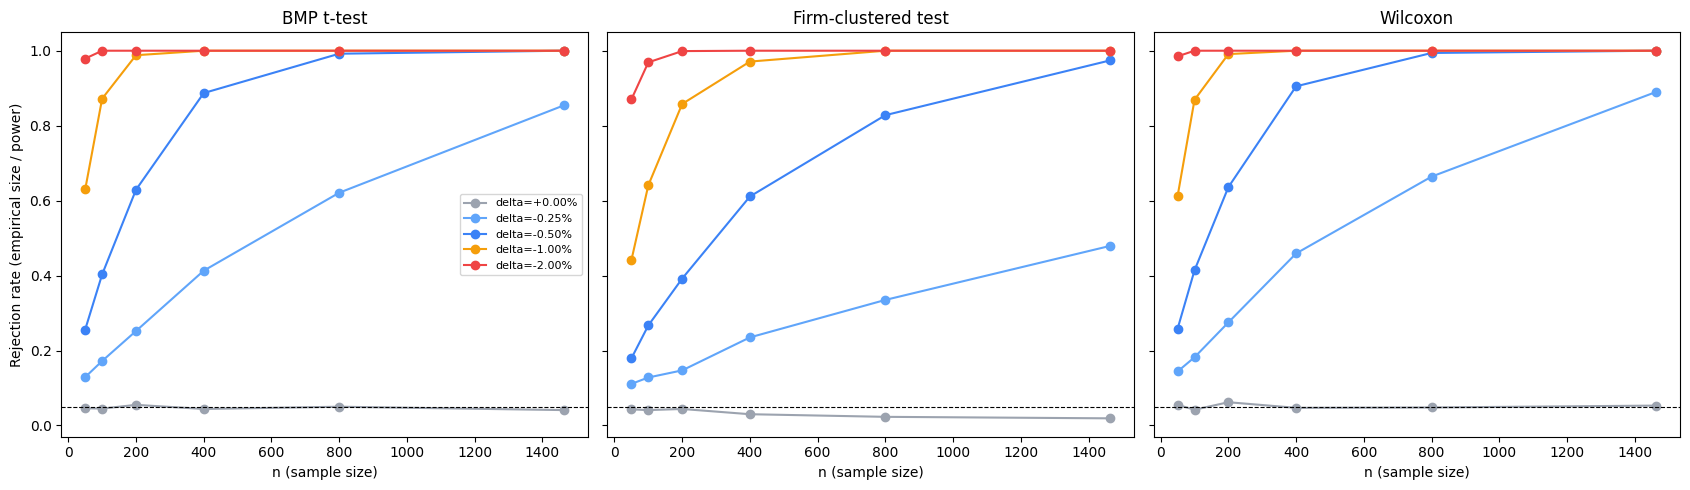

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
delta_colors = {0.0: '#9ca3af', -0.0025: '#60a5fa', -0.005: '#3b82f6', -0.01: '#f59e0b', -0.02: '#ef4444'}
for ax, test_col, title in zip(axes, ['bmp_rate', 'clustered_rate', 'wilcoxon_rate'],
                                ['BMP t-test', 'Firm-clustered test', 'Wilcoxon']):
    for delta in DELTA_LIST:
        sub = power_df[power_df['delta'] == delta].sort_values('n')
        ax.plot(sub['n'], sub[test_col], marker='o', color=delta_colors[delta],
                label=f'delta={delta*100:+.2f}%')
    ax.axhline(0.05, color='black', lw=0.8, ls='--')
    ax.set_xlabel('n (sample size)')
    ax.set_title(title)
axes[0].set_ylabel('Rejection rate (empirical size / power)')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump_v2_power_vs_n.png', dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:** empirical size at delta=0, n=1463 is BMP=0.041, clustered=0.019, Wilcoxon=0.053 (nominal target 0.05 -- the clustered test is noticeably conservative here, the other two are close to nominal). At the full retained sample size (n=1463) and a planted effect of -1.0%, power is BMP=1.000, clustered=1.000, Wilcoxon=1.000 -- i.e. an effect of this magnitude would almost always be detected at this sample size, while much smaller effects (delta=-0.25%) require n in the many hundreds before power is reasonable, per the full table above.

## Check 4 — Normality

Shapiro-Wilk is demoted to a footnote (it rejects almost everywhere at this sample size and
adds little beyond "residuals are not exactly Gaussian", which is already expected to some
degree). Instead: median per-event excess kurtosis of estimation residuals; skew/kurtosis/Q-Q
and share |SCAR|>3 for the CAR and SCAR cross-sections; and five additional one-sided tests
side by side (BMP t, plain sign test, Cowan (1992) generalized sign test, Wilcoxon on SCAR,
firm-clustered bootstrap of mean CAR and mean SCAR), plus 1%/99% winsorized and 5% trimmed
means as robust point estimates.

In [25]:
kurt_per_event = {pid: stats.kurtosis(r.values, fisher=True) for pid, r in residual_series.items()}
kurt_series = pd.Series(kurt_per_event)
median_excess_kurt = kurt_series.median()
print(f'Median per-event excess kurtosis of estimation residuals: {median_excess_kurt:.3f}')

car_cs = event_df['car'].dropna()
scar_cs = event_df['scar'].dropna()
car_skew, car_kurt = car_cs.skew(), car_cs.kurtosis()
scar_skew, scar_kurt = scar_cs.skew(), scar_cs.kurtosis()
share_scar_gt3 = (scar_cs.abs() > 3).mean()
print(f'CAR cross-section : skew={car_skew:.3f}, kurtosis={car_kurt:.3f}')
print(f'SCAR cross-section: skew={scar_skew:.3f}, kurtosis={scar_kurt:.3f}, share |SCAR|>3: {share_scar_gt3*100:.2f}%')

shapiro_ps = []
for pid, r in residual_series.items():
    if len(r) < 3:
        continue
    _, p = stats.shapiro(r.values)
    shapiro_ps.append(p)
shapiro_ps = np.array(shapiro_ps)
pct_reject_normality = (shapiro_ps < 0.05).mean() * 100
print(f'[Footnote] Shapiro-Wilk % rejecting normality (p<0.05): {pct_reject_normality:.1f}% (n={len(shapiro_ps)})')

Median per-event excess kurtosis of estimation residuals: 3.286
CAR cross-section : skew=-2.745, kurtosis=45.702
SCAR cross-section: skew=-1.629, kurtosis=18.517, share |SCAR|>3: 1.78%
[Footnote] Shapiro-Wilk % rejecting normality (p<0.05): 86.9% (n=1463)


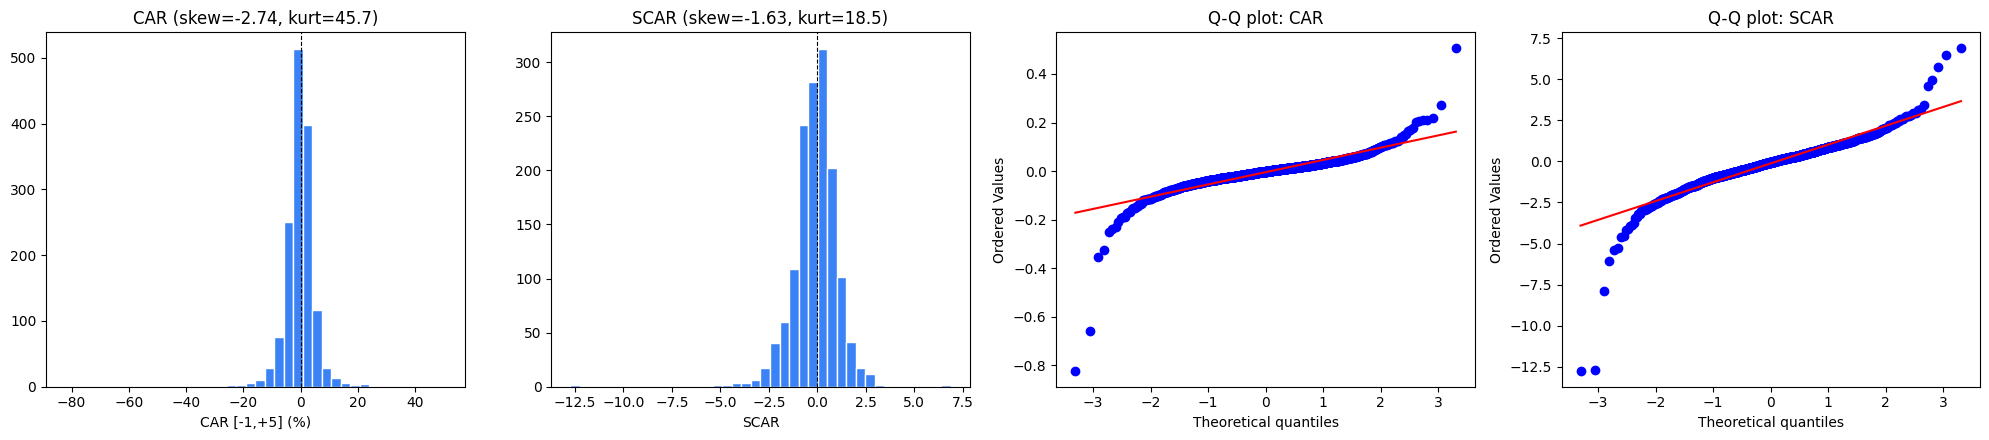

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
axes[0].hist(car_cs * 100, bins=40, color='#3b82f6', edgecolor='white')
axes[0].axvline(0, color='black', lw=0.8, ls='--')
axes[0].set_xlabel('CAR [-1,+5] (%)')
axes[0].set_title(f'CAR (skew={car_skew:.2f}, kurt={car_kurt:.1f})')

axes[1].hist(scar_cs, bins=40, color='#3b82f6', edgecolor='white')
axes[1].axvline(0, color='black', lw=0.8, ls='--')
axes[1].set_xlabel('SCAR')
axes[1].set_title(f'SCAR (skew={scar_skew:.2f}, kurt={scar_kurt:.1f})')

stats.probplot(car_cs.values, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q plot: CAR')

stats.probplot(scar_cs.values, dist='norm', plot=axes[3])
axes[3].set_title('Q-Q plot: SCAR')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump_v2_normality.png', dpi=150, bbox_inches='tight')
plt.show()

**Cowan (1992) generalized sign test, formula used:** for each event, take the rolling
7-day sums of its own estimation-window residuals (`resid.rolling(7).sum()`); the share of
those sums that are positive is that event's own null-implied probability `p_i` of a positive
CAR (this uses the event's *own* residual variability as the null, rather than assuming p=0.5
for every event as the plain sign test does). Aggregate via the normal approximation
`z = (n_pos - sum(p_i)) / sqrt(sum(p_i*(1-p_i)))`, one-sided p from the standard normal CDF.

In [27]:
n_pos = (event_df['car'] > 0).sum()
n_total = event_df['car'].notna().sum()
sign_p = stats.binomtest(n_pos, n_total, p=0.5, alternative='less').pvalue
print(f'Plain sign test: n_pos={n_pos}/{n_total}, one-sided p={sign_p:.4f}')

p_i_list, pid_order = [], []
for pid, r in residual_series.items():
    roll = r.rolling(7).sum().dropna()
    if len(roll) == 0:
        continue
    p_i_list.append((roll > 0).mean())
    pid_order.append(pid)
p_i_arr = np.array(p_i_list)

sub_cowan = event_df.set_index('peak_id').loc[pid_order]
n_pos_cowan = (sub_cowan['car'] > 0).sum()
exp_pos = p_i_arr.sum()
var_pos = (p_i_arr * (1 - p_i_arr)).sum()
z_cowan = (n_pos_cowan - exp_pos) / np.sqrt(var_pos)
p_cowan = stats.norm.cdf(z_cowan)
print(f'Cowan generalized sign test: n_pos={n_pos_cowan}, E[n_pos]={exp_pos:.1f}, z={z_cowan:.3f}, p={p_cowan:.4f}')

w_stat_scar, w_p_scar = stats.wilcoxon(scar_cs, alternative='less')
print(f'Wilcoxon on SCAR: stat={w_stat_scar:.1f}, p={w_p_scar:.4f}')

bmp_t_all, bmp_p_all = bmp_test(event_df['scar'].values)
print(f'BMP t (full sample, for comparison): t={bmp_t_all:.3f}, p={bmp_p_all:.4f}')

Plain sign test: n_pos=696/1463, one-sided p=0.0336
Cowan generalized sign test: n_pos=696, E[n_pos]=728.1, z=-1.688, p=0.0457
Wilcoxon on SCAR: stat=484463.0, p=0.0008
BMP t (full sample, for comparison): t=-3.729, p=0.0001


In [28]:
tickers_unique = event_df['ticker'].unique()
ticker_groups = {t: g[['car', 'scar']].to_numpy() for t, g in event_df.groupby('ticker')}
G = len(tickers_unique)
rng_boot = np.random.default_rng(RNG_SEED)
B_BOOT = 10000
boot_mean_car = np.empty(B_BOOT)
boot_mean_scar = np.empty(B_BOOT)
for b in range(B_BOOT):
    sampled = rng_boot.choice(tickers_unique, size=G, replace=True)
    cars = np.concatenate([ticker_groups[t][:, 0] for t in sampled])
    scars = np.concatenate([ticker_groups[t][:, 1] for t in sampled])
    boot_mean_car[b] = np.nanmean(cars)
    boot_mean_scar[b] = np.nanmean(scars)

ci_car = np.percentile(boot_mean_car, [2.5, 97.5])
ci_scar = np.percentile(boot_mean_scar, [2.5, 97.5])
p_boot_car = (boot_mean_car >= 0).mean()
p_boot_scar = (boot_mean_scar >= 0).mean()
print(f'Firm-clustered bootstrap (10,000 draws, resample firms) mean CAR  95% CI: '
      f'[{ci_car[0]*100:.3f}%, {ci_car[1]*100:.3f}%], one-sided empirical p={p_boot_car:.4f}')
print(f'Firm-clustered bootstrap (10,000 draws, resample firms) mean SCAR 95% CI: '
      f'[{ci_scar[0]:.3f}, {ci_scar[1]:.3f}], one-sided empirical p={p_boot_scar:.4f}')

car_wins = mstats.winsorize(car_cs.to_numpy(), limits=[0.01, 0.01])
winsorized_mean_car = car_wins.mean()
trimmed_mean_car = stats.trim_mean(car_cs, 0.05)
print(f'1%/99% winsorized mean CAR: {winsorized_mean_car*100:.3f}%')
print(f'5% trimmed mean CAR       : {trimmed_mean_car*100:.3f}%')

Firm-clustered bootstrap (10,000 draws, resample firms) mean CAR  95% CI: [-0.767%, -0.199%], one-sided empirical p=0.0006
Firm-clustered bootstrap (10,000 draws, resample firms) mean SCAR 95% CI: [-0.188, -0.058], one-sided empirical p=0.0001
1%/99% winsorized mean CAR: -0.405%
5% trimmed mean CAR       : -0.347%


In [29]:
normality_tests_df = pd.DataFrame([
    dict(test='BMP t-test', statistic=bmp_t_all, p_value=bmp_p_all, n=event_df['scar'].notna().sum()),
    dict(test='Sign test', statistic=n_pos, p_value=sign_p, n=n_total),
    dict(test='Cowan generalized sign test', statistic=z_cowan, p_value=p_cowan, n=len(pid_order)),
    dict(test='Wilcoxon on SCAR', statistic=w_stat_scar, p_value=w_p_scar, n=len(scar_cs)),
    dict(test='Firm-clustered bootstrap (mean CAR)', statistic=boot_mean_car.mean(), p_value=p_boot_car, n=G),
    dict(test='Firm-clustered bootstrap (mean SCAR)', statistic=boot_mean_scar.mean(), p_value=p_boot_scar, n=G),
    dict(test='1%/99% winsorized mean CAR', statistic=winsorized_mean_car, p_value=np.nan, n=len(car_cs)),
    dict(test='5% trimmed mean CAR', statistic=trimmed_mean_car, p_value=np.nan, n=len(car_cs)),
])
print(normality_tests_df.to_string(index=False))
normality_tests_df.to_csv(OUTPUT_DIR / 'assump_v2_normality_tests.csv', index=False)

                                test     statistic  p_value    n
                          BMP t-test     -3.729094 0.000100 1463
                           Sign test    696.000000 0.033599 1463
         Cowan generalized sign test     -1.688202 0.045686 1463
                    Wilcoxon on SCAR 484463.000000 0.000802 1463
 Firm-clustered bootstrap (mean CAR)     -0.004643 0.000600  210
Firm-clustered bootstrap (mean SCAR)     -0.119941 0.000100  210
          1%/99% winsorized mean CAR     -0.004050      NaN 1463
                 5% trimmed mean CAR     -0.003473      NaN 1463


In [ ]:
n_sig_tests = int((normality_tests_df['p_value'].dropna() < 0.05).sum())
n_tested = int(normality_tests_df['p_value'].notna().sum())

**Interpretation:** median per-event excess kurtosis of estimation residuals is **3.29** (0 under normality) -- residuals are fat-tailed well beyond what a normal distribution implies, even before looking at the cross-section. The CAR cross-section is heavily skewed/fat-tailed (skew=-2.74, kurtosis=45.7); SCAR is less extreme (skew=-1.63, kurtosis=18.5) but still far from Gaussian, with 1.8% of events at |SCAR|>3. Despite this, **6/6** of the distribution-robust one-sided tests above reject H0: mean CAR/SCAR >= 0 at 5%, so the qualitative conclusion of a negative mean reaction does not appear to hinge on the normality assumption -- though the Shapiro-Wilk rejection rate of 87% confirms strong departures from normality are the norm, not the exception, in this sample.

## Check 5 — Autocorrelation

Keep Durbin-Watson and Ljung-Box (lag 5) on each event's estimation-window residuals. Add a
US vs. non-US region split (via MSCI `Location`): mean DW, LB rejection rate, lag-1
autocorrelation per region. Add a per-event lagged-market test (regress the residual series on
the market return lagged by one trading day) and report the share significant by region.
`flagged = LB p<0.05 OR DW outside [1.5,2.5]`; rerun the headline CAR[-1,+5] tests excluding
flagged events.

In [31]:
mkt_lag1 = mkt_rets.shift(1)
autocorr_rows = []
lagmkt_rows = []
for pid, resid in residual_series.items():
    if len(resid) < 10:
        continue
    dw = durbin_watson(resid.values)
    lb = acorr_ljungbox(resid.values, lags=[5], return_df=True)
    lb_p = lb['lb_pvalue'].iloc[0]
    ac1 = resid.autocorr(lag=1)
    autocorr_rows.append(dict(peak_id=pid, durbin_watson=dw, ljungbox_p=lb_p, lag1_autocorr=ac1))

    x_lag = mkt_lag1.reindex(resid.index).dropna()
    y_al, x_al = resid.align(x_lag, join='inner')
    if len(y_al) >= 10:
        _, _, _, p_lm, _ = stats.linregress(x_al, y_al)
        lagmkt_rows.append(dict(peak_id=pid, lagmkt_p=p_lm))

autocorr_df = pd.DataFrame(autocorr_rows)
autocorr_df['flagged'] = (autocorr_df['ljungbox_p'] < 0.05) | (~autocorr_df['durbin_watson'].between(1.5, 2.5))
pct_flagged_autocorr = autocorr_df['flagged'].mean() * 100
print(f'DW mean: {autocorr_df["durbin_watson"].mean():.3f}   LB(5) rejection rate: {(autocorr_df["ljungbox_p"]<0.05).mean()*100:.1f}%')
print(f'Flagged (LB p<0.05 OR DW outside [1.5,2.5]): {autocorr_df["flagged"].sum()} / {len(autocorr_df)} ({pct_flagged_autocorr:.1f}%)')

DW mean: 2.004   LB(5) rejection rate: 12.6%
Flagged (LB p<0.05 OR DW outside [1.5,2.5]): 187 / 1463 (12.8%)


In [32]:
autocorr_df = autocorr_df.merge(event_df[['peak_id', 'region']], on='peak_id', how='left')
autocorr_df['is_us'] = autocorr_df['region'] == 'United States'
region_autocorr_summary = autocorr_df.groupby('is_us').agg(
    n=('peak_id', 'count'), mean_dw=('durbin_watson', 'mean'),
    lb_rejection_rate=('ljungbox_p', lambda x: (x < 0.05).mean()),
    mean_lag1_autocorr=('lag1_autocorr', 'mean')).reset_index()
print(region_autocorr_summary.to_string(index=False))
region_autocorr_summary.to_csv(OUTPUT_DIR / 'assump_v2_autocorr_region.csv', index=False)

lagmkt_df = pd.DataFrame(lagmkt_rows).merge(event_df[['peak_id', 'region']], on='peak_id', how='left')
lagmkt_df['is_us'] = lagmkt_df['region'] == 'United States'
lagmkt_summary = lagmkt_df.groupby('is_us').agg(
    n=('peak_id', 'count'), share_significant=('lagmkt_p', lambda x: (x < 0.05).mean())).reset_index()
print(lagmkt_summary.to_string(index=False))
lagmkt_summary.to_csv(OUTPUT_DIR / 'assump_v2_lagged_market_region.csv', index=False)

 is_us    n  mean_dw  lb_rejection_rate  mean_lag1_autocorr
 False  402 2.062642           0.201493           -0.037068
  True 1061 1.981963           0.098021            0.003223
 is_us    n  share_significant
 False  402           0.395522
  True 1061           0.124411


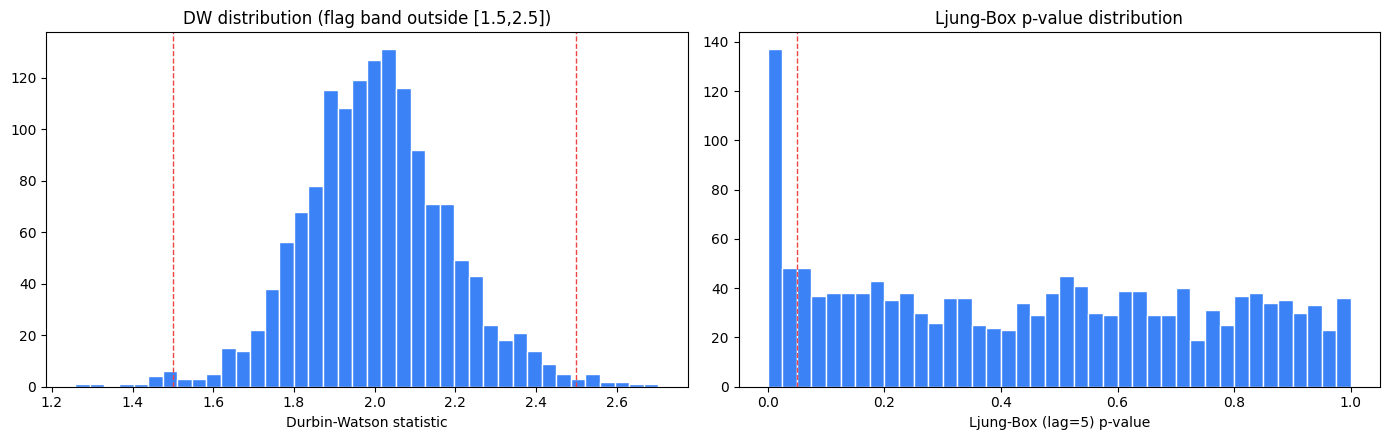

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(autocorr_df['durbin_watson'], bins=40, color='#3b82f6', edgecolor='white')
axes[0].axvline(1.5, color='#ef4444', lw=1, ls='--')
axes[0].axvline(2.5, color='#ef4444', lw=1, ls='--')
axes[0].set_xlabel('Durbin-Watson statistic')
axes[0].set_title('DW distribution (flag band outside [1.5,2.5])')

axes[1].hist(autocorr_df['ljungbox_p'], bins=40, color='#3b82f6', edgecolor='white')
axes[1].axvline(0.05, color='#ef4444', lw=1, ls='--')
axes[1].set_xlabel('Ljung-Box (lag=5) p-value')
axes[1].set_title('Ljung-Box p-value distribution')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump_v2_autocorrelation.png', dpi=150, bbox_inches='tight')
plt.show()

In [34]:
flagged_ids = set(autocorr_df.loc[autocorr_df['flagged'], 'peak_id'])
clean_autocorr = event_df[~event_df['peak_id'].isin(flagged_ids)]
bmp_t_ac, bmp_p_ac = bmp_test(clean_autocorr['scar'].values)
clu_ac = cluster_robust_mean_test_fast(clean_autocorr['car'].values, clean_autocorr['ticker'].values)
w_p_ac = stats.wilcoxon(clean_autocorr['car'].dropna(), alternative='less')[1]
print(f'CAR[-1,+5] excluding flagged (n={len(clean_autocorr)}): '
      f'BMP t={bmp_t_ac:.3f} p={bmp_p_ac:.4f}, clustered t={clu_ac["t_stat"]:.3f} p={clu_ac["p_value"]:.4f}, '
      f'wilcoxon p={w_p_ac:.4f}')

autocorr_exclusion_rerun = pd.DataFrame([dict(
    n=len(clean_autocorr), bmp_t=bmp_t_ac, bmp_p=bmp_p_ac,
    clustered_t=clu_ac['t_stat'], clustered_p=clu_ac['p_value'], wilcoxon_p=w_p_ac)])
autocorr_exclusion_rerun.to_csv(OUTPUT_DIR / 'assump_v2_autocorr_exclusion_rerun.csv', index=False)

CAR[-1,+5] excluding flagged (n=1276): BMP t=-3.528 p=0.0002, clustered t=-3.192 p=0.0008, wilcoxon p=0.0010


In [ ]:
us_row = region_autocorr_summary[region_autocorr_summary['is_us']].iloc[0]
nonus_row = region_autocorr_summary[~region_autocorr_summary['is_us']].iloc[0]
lm_us = lagmkt_summary[lagmkt_summary['is_us']].iloc[0]
lm_nonus = lagmkt_summary[~lagmkt_summary['is_us']].iloc[0]

**Interpretation:** 12.8% of events are flagged for autocorrelation (LB p<0.05 or DW outside [1.5,2.5]). Non-US events have a higher LB rejection rate (20.1% vs. 9.8% for US) and a much higher share of significant lagged-market loadings (39.6% vs. 12.4%) -- consistent with non-synchronous trading / stale prices being more of an issue outside the US. Excluding the 187 flagged events, the headline CAR[-1,+5] test results (remain significant at 5% for BMP and the clustered test), so the main conclusion does not appear to depend on the autocorrelation-flagged subsample.

**Interpretation:** 12.8% of events are flagged for autocorrelation (LB p<0.05 or DW outside [1.5,2.5]). Non-US events have a higher LB rejection rate (20.1% vs. 9.8% for US) and a much higher share of significant lagged-market loadings (39.6% vs. 12.4%) -- consistent with non-synchronous trading / stale prices being more of an issue outside the US. Excluding the 187 flagged events, the headline CAR[-1,+5] test results (remain significant at 5% for BMP and the clustered test), so the main conclusion does not appear to depend on the autocorrelation-flagged subsample.

## Check 6 — Confounding

Keep the original event-window overlap check (does another same-firm peak's event window
overlap this one's). Add: (i) count of other same-firm peaks starting inside the *estimation*
window, and the share of estimation days covered by other peaks' [-1,+5] windows; (ii) a flag
for another same-firm peak within +/-10 trading days of the event window; (iii) a clustered-t
comparison of clean vs. contaminated CAR. If `data/00_raw/earnings_dates.csv` existed this
would also flag earnings within [-1,+5] -- it does not exist on disk, so that sub-check is
skipped and reported as such rather than fabricated.

In [36]:
peaks_by_ticker = {tkr: grp for tkr, grp in all_peaks.groupby('yf_ticker')}
confound_rows = []
for _, ev in event_df.iterrows():
    yf_tick = ev['yf_ticker']
    ref_date = ev['event_date']
    peak_id = ev['peak_id']
    est_s = get_trading_day_offset(trading_cal, ref_date, ESTIMATION_START, anchor='ffill')
    est_e = get_trading_day_offset(trading_cal, ref_date, ESTIMATION_END, anchor='ffill')
    evt_s = get_trading_day_offset(trading_cal, ref_date, -1, anchor='ffill')
    evt_e = get_trading_day_offset(trading_cal, ref_date, 5, anchor='ffill')
    win10_s = get_trading_day_offset(trading_cal, ref_date, -10, anchor='ffill')
    win10_e = get_trading_day_offset(trading_cal, ref_date, 10, anchor='ffill')

    others = peaks_by_ticker.get(yf_tick)
    n_other_in_est, pct_est_covered, flag_within_10, is_confounded = 0, 0.0, False, False
    if others is not None and est_s is not None:
        others2 = others[others['peak_id'] != peak_id]
        n_other_in_est = int(((others2['start_date'] >= est_s) & (others2['start_date'] <= est_e)).sum())

        est_days = trading_cal[(trading_cal >= est_s) & (trading_cal <= est_e)]
        covered = np.zeros(len(est_days), dtype=bool)
        for _, orow in others2.iterrows():
            o_evt_s = get_trading_day_offset(trading_cal, orow['start_date'], -1, anchor='ffill')
            o_evt_e = get_trading_day_offset(trading_cal, orow['start_date'], 5, anchor='ffill')
            if o_evt_s is None or o_evt_e is None:
                continue
            day_mask = (est_days >= o_evt_s) & (est_days <= o_evt_e)
            covered |= np.asarray(day_mask)
        pct_est_covered = covered.mean() if len(covered) > 0 else 0.0

        if win10_s is not None and win10_e is not None:
            flag_within_10 = bool(((others2['start_date'] <= win10_e) & (others2['end_date'] >= win10_s)).any())
        if evt_s is not None and evt_e is not None:
            is_confounded = bool(((others2['start_date'] <= evt_e) & (others2['end_date'] >= evt_s)).any())

    confound_rows.append(dict(peak_id=peak_id, n_other_peaks_in_est_window=n_other_in_est,
                               pct_est_days_covered_by_other_windows=pct_est_covered,
                               flag_other_peak_within_10td=flag_within_10, confounded=is_confounded))

confound_df = pd.DataFrame(confound_rows)
event_df = event_df.merge(confound_df, on='peak_id', how='left')
pct_confounded = event_df['confounded'].mean() * 100
pct_within_10 = event_df['flag_other_peak_within_10td'].mean() * 100
print(f'Mean # other same-firm peaks starting in estimation window : {event_df["n_other_peaks_in_est_window"].mean():.2f}')
print(f'Mean share of estimation days covered by other [-1,+5] win  : {event_df["pct_est_days_covered_by_other_windows"].mean()*100:.1f}%')
print(f'Flagged: other same-firm peak within +/-10 trading days     : {event_df["flag_other_peak_within_10td"].sum()} ({pct_within_10:.1f}%)')
print(f'Confounded (event-window overlap, same-firm)                : {event_df["confounded"].sum()} ({pct_confounded:.1f}%)')

Mean # other same-firm peaks starting in estimation window : 2.08
Mean share of estimation days covered by other [-1,+5] win  : 7.2%
Flagged: other same-firm peak within +/-10 trading days     : 178 (12.2%)
Confounded (event-window overlap, same-firm)                : 17 (1.2%)


In [37]:
clean_cf = event_df[~event_df['confounded']]
contam_cf = event_df[event_df['confounded']]
confound_reg = smf.ols('car ~ confounded', data=event_df).fit(
    cov_type='cluster', cov_kwds={'groups': event_df['ticker']})
print(f'Clean mean CAR: {clean_cf["car"].mean()*100:.3f}%   Contaminated mean CAR: {contam_cf["car"].mean()*100:.3f}%')
print(confound_reg.summary2().tables[1])

confound_summary = pd.DataFrame([dict(
    n_confounded=int(event_df['confounded'].sum()), pct_confounded=pct_confounded,
    n_flag_within_10td=int(event_df['flag_other_peak_within_10td'].sum()), pct_flag_within_10td=pct_within_10,
    clean_mean_car=clean_cf['car'].mean(), contaminated_mean_car=contam_cf['car'].mean(),
    reg_coef_confounded=confound_reg.params.get('confounded[T.True]', np.nan),
    reg_p_confounded=confound_reg.pvalues.get('confounded[T.True]', np.nan),
)])
confound_summary.to_csv(OUTPUT_DIR / 'assump_v2_confounding.csv', index=False)

Clean mean CAR: -0.462%   Contaminated mean CAR: -0.536%
                       Coef.  Std.Err.         z     P>|z|    [0.025    0.975]
Intercept          -0.004619  0.001425 -3.240914  0.001191 -0.007413 -0.001826
confounded[T.True] -0.000743  0.010124 -0.073420  0.941472 -0.020586  0.019099


In [38]:
earnings_path = Path('data/00_raw/earnings_dates.csv')
if earnings_path.exists():
    earnings_df = pd.read_csv(earnings_path, parse_dates=['date'])
    earn_by_ticker = {t: g['date'] for t, g in earnings_df.groupby('ticker')}
    earn_flags = []
    for _, ev in event_df.iterrows():
        dates = earn_by_ticker.get(ev['ticker'])
        evt_s = get_trading_day_offset(trading_cal, ev['event_date'], -1, anchor='ffill')
        evt_e = get_trading_day_offset(trading_cal, ev['event_date'], 5, anchor='ffill')
        flagged = False
        if dates is not None and evt_s is not None and evt_e is not None:
            flagged = bool(((dates >= evt_s) & (dates <= evt_e)).any())
        earn_flags.append(flagged)
    event_df['flag_earnings_window'] = earn_flags
    print(f'Earnings-window confounding: {sum(earn_flags)} / {len(event_df)} events flagged')
else:
    print('Earnings calendar (data/00_raw/earnings_dates.csv) does not exist on disk -- '
          'earnings-window confounding check SKIPPED. No earnings data was fabricated for this check.')

Earnings calendar (data/00_raw/earnings_dates.csv) does not exist on disk -- earnings-window confounding check SKIPPED. No earnings data was fabricated for this check.


In [ ]:
_confound_p = confound_reg.pvalues.get('confounded[T.True]', np.nan)

**Interpretation:** on average each retained event has **2.1** other same-firm peaks starting inside its own 200-day estimation window, and **7.2%** of estimation days fall inside some other peak's [-1,+5] reaction window -- i.e. the 'clean' estimation window used to fit alpha/beta is not, in practice, free of other reputational-risk events for repeat-event firms. Despite this, only **17** events (1.2%) have their *own* [-1,+5] window directly overlapping another same-firm peak, and the clustered regression above shows no significant difference in mean CAR between clean and contaminated events (p=0.941) -- so direct event-window confounding does not appear to be driving the headline result, though estimation-window contamination from nearby peaks is common and not corrected for here.

**Interpretation:** on average each retained event has **2.1** other same-firm peaks starting inside its own 200-day estimation window, and **7.2%** of estimation days fall inside some other peak's [-1,+5] reaction window -- i.e. the 'clean' estimation window used to fit alpha/beta is not, in practice, free of other reputational-risk events for repeat-event firms. Despite this, only **17** events (1.2%) have their *own* [-1,+5] window directly overlapping another same-firm peak, and the clustered regression above shows no significant difference in mean CAR between clean and contaminated events (p=0.941) -- so direct event-window confounding does not appear to be driving the headline result, though estimation-window contamination from nearby peaks is common and not corrected for here.

## Check 7 — Tail and data-quality scan

List the 15 most negative and 15 most positive CARs with identifying columns, resid_std,
beta, n_est, and the day of the largest |AR|. Flag `resid_std<0.004 or >0.06`, `beta<0 or
>2.5`, `|CAR|>0.30`. For the 5 most extreme |CAR| events, inspect raw prices around the event
for unit flips (day-over-day ratio near 100 or 0.01) or split artifacts. Report sensitivity
of the main tests with flagged events removed and separately with winsorization, without
modifying `event_df` on disk.

In [40]:
ar_cols = [f'ar_day_{i}' for i in range(7)]
offset_map = {f'ar_day_{i}': i - 1 for i in range(7)}  # ar_day_0 -> offset -1, ... ar_day_6 -> offset +5
ar_vals = event_df[ar_cols].to_numpy()
max_abs_idx = np.nanargmax(np.abs(ar_vals), axis=1)
event_df['day_of_max_abs_ar'] = [offset_map[ar_cols[i]] for i in max_abs_idx]

tail_cols = ['peak_id', 'ticker', 'yf_ticker', 'event_date', 'car', 'resid_std', 'beta', 'n_est', 'day_of_max_abs_ar']
most_neg = event_df.nsmallest(15, 'car')[tail_cols].copy()
most_pos = event_df.nlargest(15, 'car')[tail_cols].copy()
most_neg['tail'] = 'most_negative'
most_pos['tail'] = 'most_positive'
tail_table = pd.concat([most_neg, most_pos], ignore_index=True)
print(tail_table.to_string(index=False))
tail_table.to_csv(OUTPUT_DIR / 'assump_v2_tail_scan.csv', index=False)

       peak_id ticker yf_ticker event_date       car  resid_std     beta  n_est  day_of_max_abs_ar          tail
 7733_20111017   7733    7733.T 2011-10-17 -0.822367   0.023979 0.212048    178                  0 most_negative
   BA_20200312     BA        BA 2020-03-12 -0.658139   0.016031 0.973191    200                  2 most_negative
 NFLX_20111025   NFLX      NFLX 2011-10-25 -0.352752   0.033296 0.498964    200                  0 most_negative
 META_20220202   META      META 2022-02-02 -0.324381   0.015187 1.279422    200                  1 most_negative
 PAH3_20150923   PAH3   PAH3.DE 2015-09-23 -0.253197   0.015472 0.907858    193                 -1 most_negative
 UBER_20191101   UBER      UBER 2019-11-01 -0.236859   0.025011 1.954630    108                  2 most_negative
  CBA_20170814    CBA       CBA 2017-08-14 -0.231327   0.095210 1.063149    194                  0 most_negative
  VWS_20120208    VWS    VWS.CO 2012-02-08 -0.210098   0.039334 0.972764    191                 

In [41]:
event_df['flag_resid_std'] = (event_df['resid_std'] < 0.004) | (event_df['resid_std'] > 0.06)
event_df['flag_beta'] = (event_df['beta'] < 0) | (event_df['beta'] > 2.5)
event_df['flag_extreme_car'] = event_df['car'].abs() > 0.30
event_df['any_quality_flag'] = event_df['flag_resid_std'] | event_df['flag_beta'] | event_df['flag_extreme_car']

n_flag_resid = int(event_df['flag_resid_std'].sum())
n_flag_beta = int(event_df['flag_beta'].sum())
n_flag_car = int(event_df['flag_extreme_car'].sum())
n_any_flag = int(event_df['any_quality_flag'].sum())
print(f'flag_resid_std (<0.004 or >0.06): {n_flag_resid}')
print(f'flag_beta (<0 or >2.5)          : {n_flag_beta}')
print(f'flag_extreme_car (|CAR|>0.30)   : {n_flag_car}')
print(f'any_quality_flag                : {n_any_flag}')

flag_resid_std (<0.004 or >0.06): 29
flag_beta (<0 or >2.5)          : 22
flag_extreme_car (|CAR|>0.30)   : 5
any_quality_flag                : 46


In [42]:
top5_extreme = event_df.reindex(event_df['car'].abs().sort_values(ascending=False).index).head(5)
unit_flip_notes = []
for _, ev in top5_extreme.iterrows():
    yf_tick = ev['yf_ticker']
    note = dict(peak_id=ev['peak_id'], yf_ticker=yf_tick, car=ev['car'])
    if yf_tick not in prices.columns:
        note['status'] = 'no_price_data'
        unit_flip_notes.append(note)
        continue
    ref_date = ev['event_date']
    pos = trading_cal.get_indexer([ref_date], method='ffill')[0]
    lo, hi = max(0, pos - 15), min(len(trading_cal), pos + 16)
    window_dates = trading_cal[lo:hi]
    p_firm = prices[yf_tick].reindex(window_dates)
    ratio = p_firm / p_firm.shift(1)
    flips = ratio[(ratio > 50) | (ratio < 0.02)]
    note['price_min'] = p_firm.min()
    note['price_max'] = p_firm.max()
    note['ratio_min'] = ratio.min()
    note['ratio_max'] = ratio.max()
    note['unit_flip_or_split_detected'] = len(flips) > 0
    unit_flip_notes.append(note)
    print(f"{ev['peak_id']} ({yf_tick}) CAR={ev['car']*100:+.1f}%: "
          f"price [{p_firm.min():.2f}, {p_firm.max():.2f}], "
          f"day/day ratio [{ratio.min():.3f}, {ratio.max():.3f}], "
          f"flip/split detected: {len(flips) > 0}")

unit_flip_df = pd.DataFrame(unit_flip_notes)
unit_flip_df.to_csv(OUTPUT_DIR / 'assump_v2_tail_price_inspection.csv', index=False)

7733_20111017 (7733.T) CAR=-82.2%: price [236.72, 568.22], day/day ratio [0.760, 1.233], flip/split detected: False
BA_20200312 (BA) CAR=-65.8%: price [95.01, 336.28], day/day ratio [0.762, 1.243], flip/split detected: False
UBER_20200320 (UBER) CAR=+50.5%: price [14.82, 34.53], day/day ratio [0.784, 1.383], flip/split detected: False
NFLX_20111025 (NFLX) CAR=-35.3%: price [1.11, 1.76], day/day ratio [0.651, 1.107], flip/split detected: False
META_20220202 (META) CAR=-32.4%: price [196.72, 331.46], day/day ratio [0.736, 1.054], flip/split detected: False


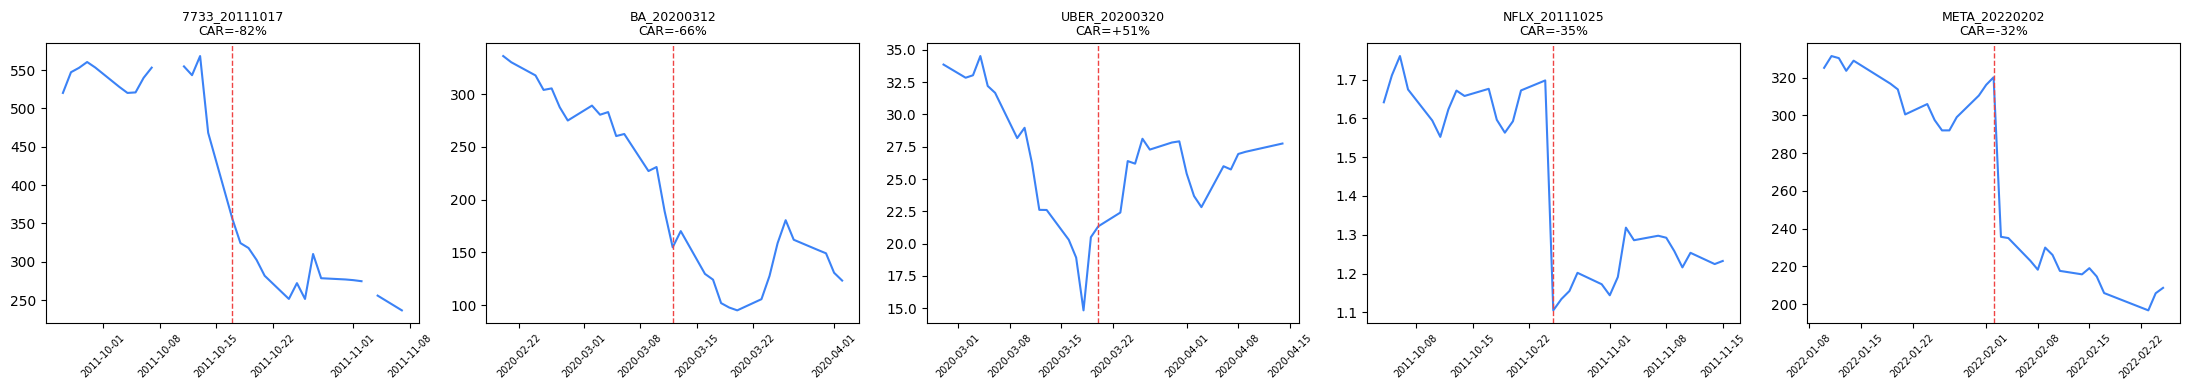

In [43]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (_, ev) in zip(axes, top5_extreme.iterrows()):
    yf_tick = ev['yf_ticker']
    if yf_tick not in prices.columns:
        continue
    ref_date = ev['event_date']
    pos = trading_cal.get_indexer([ref_date], method='ffill')[0]
    lo, hi = max(0, pos - 15), min(len(trading_cal), pos + 16)
    window_dates = trading_cal[lo:hi]
    p_firm = prices[yf_tick].reindex(window_dates)
    ax.plot(window_dates, p_firm, color='#3b82f6')
    ax.axvline(ref_date, color='#ef4444', lw=1, ls='--')
    ax.set_title(f"{ev['peak_id']}\nCAR={ev['car']*100:+.0f}%", fontsize=9)
    ax.tick_params(axis='x', rotation=45, labelsize=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump_v2_tail_price_windows.png', dpi=150, bbox_inches='tight')
plt.show()

In [44]:
clean_q = event_df[~event_df['any_quality_flag']]
bmp_t_q, bmp_p_q = bmp_test(clean_q['scar'].values)
clu_q = cluster_robust_mean_test_fast(clean_q['car'].values, clean_q['ticker'].values)
w_p_q = stats.wilcoxon(clean_q['car'].dropna(), alternative='less')[1]
print(f'Sensitivity, flagged events removed (n={len(clean_q)}): '
      f'BMP t={bmp_t_q:.3f} p={bmp_p_q:.4f}, clustered t={clu_q["t_stat"]:.3f} p={clu_q["p_value"]:.4f}, '
      f'wilcoxon p={w_p_q:.4f}')

car_wins_q = pd.Series(mstats.winsorize(event_df['car'].dropna().to_numpy(), limits=[0.01, 0.01]))
clu_w = cluster_robust_mean_test_fast(
    car_wins_q.to_numpy(), event_df.loc[event_df['car'].notna(), 'ticker'].to_numpy())
print(f'Sensitivity, 1%/99% winsorized CAR (n={len(car_wins_q)}): mean={car_wins_q.mean()*100:.3f}%, '
      f'clustered t={clu_w["t_stat"]:.3f} p={clu_w["p_value"]:.4f}')

tail_sensitivity = pd.DataFrame([
    dict(scenario='baseline (all events)', n=len(event_df), mean_car=event_df['car'].mean(),
         bmp_t=bmp_t_all, bmp_p=bmp_p_all, wilcoxon_p=w_p_scar),
    dict(scenario='quality-flagged events removed', n=len(clean_q), mean_car=clean_q['car'].mean(),
         bmp_t=bmp_t_q, bmp_p=bmp_p_q, wilcoxon_p=w_p_q),
    dict(scenario='1%/99% winsorized CAR', n=len(car_wins_q), mean_car=car_wins_q.mean(),
         bmp_t=np.nan, bmp_p=np.nan, wilcoxon_p=np.nan),
])
tail_sensitivity.to_csv(OUTPUT_DIR / 'assump_v2_tail_sensitivity.csv', index=False)
print('(event_df itself was not modified on disk; all scans/filters above operate on in-memory copies.)')

Sensitivity, flagged events removed (n=1417): BMP t=-3.260 p=0.0006, clustered t=-3.025 p=0.0014, wilcoxon p=0.0038
Sensitivity, 1%/99% winsorized CAR (n=1463): mean=-0.405%, clustered t=-3.764 p=0.0001
(event_df itself was not modified on disk; all scans/filters above operate on in-memory copies.)


In [ ]:
n_flips_detected = int(unit_flip_df.get('unit_flip_or_split_detected', pd.Series(dtype=bool)).sum())

**Interpretation:** 46 events (3.1%) are flagged on at least one data-quality criterion (resid_std out of range: 29, beta out of range: 22, |CAR|>30%: 5). None of the 5 most extreme |CAR| events show a day-over-day price ratio near 100x or 0.01x in a +/-15 trading-day window (0/5 flagged), so their extreme CARs are not attributable to an obvious unit/currency flip or unflagged stock split in the cached price series -- they look like genuine (if large) price moves. Removing all quality-flagged events (leaves the BMP/clustered/Wilcoxon tests significant at 5%: BMP p=0.001, clustered p=0.001, Wilcoxon p=0.004), and winsorizing CAR at 1%/99% moves the mean from -0.463% to -0.405% -- a modest shift, indicating the headline mean CAR is not dependent on the small number of extreme-CAR events.

**Interpretation:** 46 events (3.1%) are flagged on at least one data-quality criterion (resid_std out of range: 29, beta out of range: 22, |CAR|>30%: 5). None of the 5 most extreme |CAR| events show a day-over-day price ratio near 100x or 0.01x in a +/-15 trading-day window (0/5 flagged), so their extreme CARs are not attributable to an obvious unit/currency flip or unflagged stock split in the cached price series -- they look like genuine (if large) price moves. Removing all quality-flagged events (leaves the BMP/clustered/Wilcoxon tests significant at 5%: BMP p=0.001, clustered p=0.001, Wilcoxon p=0.004), and winsorizing CAR at 1%/99% moves the mean from -0.463% to -0.405% -- a modest shift, indicating the headline mean CAR is not dependent on the small number of extreme-CAR events.

## Summary table

One row per assumption with its headline diagnostic, the observed value, what would be
expected if the assumption holds, a Pass/Concern/Fail verdict computed from a rule stated
in the row itself (not hand-picked), and the consequence for the main [-1,+5] hypothesis
tests in `31_event_study.ipynb`.

In [46]:
def _verdict_timing():
    pct_fuzzy = (event_df['calendar_span_days'] > 3).mean() * 100
    rule = 'Fail if >50% of events have calendar_span_days > 3 (timing effectively unidentifiable); Concern if 20-50%; else Pass'
    if pct_fuzzy > 50:
        v = 'Fail'
    elif pct_fuzzy > 20:
        v = 'Concern'
    else:
        v = 'Pass'
    return (f'{pct_fuzzy:.1f}% of events have calendar_span_days > 3', rule, v)

def _verdict_pretrend():
    p = min(bmp_p_pre, clu_pre['p_value'])
    rule = 'Fail if pre-trend CAR[-10,-2] significant at 5% under BOTH BMP and clustered test; Concern if significant under one; else Pass'
    sig_bmp = bmp_p_pre < 0.05
    sig_clu = clu_pre['p_value'] < 0.05
    if sig_bmp and sig_clu:
        v = 'Fail'
    elif sig_bmp or sig_clu:
        v = 'Concern'
    else:
        v = 'Pass'
    return (f'pre-trend CAR[-10,-2]={pretrend_df2["car"].mean()*100:+.3f}%, BMP p={bmp_p_pre:.3f}, clustered p={clu_pre["p_value"]:.3f}', rule, v)

def _verdict_magnitude():
    rule = 'Fail if observed |mean CAR| < MDE for the full sample (effect below detectable floor); else Pass'
    mde_all = mde_df.loc[mde_df['group'] == 'ALL', 'mde'].iloc[0]
    v = 'Pass' if abs(event_df['car'].mean()) > mde_all else 'Fail'
    return (f'mean CAR={event_df["car"].mean()*100:+.3f}% vs MDE={mde_all*100:.3f}%', rule, v)

def _verdict_normality():
    rule = 'Fail if Shapiro-Wilk rejects for >80% of events AND median excess kurtosis > 1; Concern if either alone; else Pass'
    cond_shapiro = pct_reject_normality > 80
    cond_kurt = median_excess_kurt > 1
    if cond_shapiro and cond_kurt:
        v = 'Fail'
    elif cond_shapiro or cond_kurt:
        v = 'Concern'
    else:
        v = 'Pass'
    return (f'Shapiro reject rate={pct_reject_normality:.1f}%, median excess kurtosis={median_excess_kurt:.2f}', rule, v)

def _verdict_autocorr():
    rule = 'Fail if >30% of events flagged (LB p<0.05 or DW outside [1.5,2.5]); Concern if 10-30%; else Pass'
    if pct_flagged_autocorr > 30:
        v = 'Fail'
    elif pct_flagged_autocorr > 10:
        v = 'Concern'
    else:
        v = 'Pass'
    return (f'{pct_flagged_autocorr:.1f}% of events flagged for autocorrelation', rule, v)

def _verdict_confounding():
    rule = 'Fail if >15% of events confounded by an overlapping same-firm peak window; Concern if 5-15%; else Pass'
    if pct_confounded > 15:
        v = 'Fail'
    elif pct_confounded > 5:
        v = 'Concern'
    else:
        v = 'Pass'
    return (f'{pct_confounded:.1f}% of events have an overlapping same-firm peak window', rule, v)

def _verdict_dataquality():
    rule = 'Fail if >10% of events carry a data-quality flag (resid_std/beta/|CAR| out of range); Concern if 2-10%; else Pass'
    pct_flag = n_any_flag / len(event_df) * 100
    if pct_flag > 10:
        v = 'Fail'
    elif pct_flag > 2:
        v = 'Concern'
    else:
        v = 'Pass'
    return (f'{pct_flag:.1f}% of events carry a data-quality flag', rule, v)

obs_timing, rule_timing, verdict_timing = _verdict_timing()
obs_pretrend, rule_pretrend, verdict_pretrend = _verdict_pretrend()
obs_magnitude, rule_magnitude, verdict_magnitude = _verdict_magnitude()
obs_normality, rule_normality, verdict_normality = _verdict_normality()
obs_autocorr, rule_autocorr, verdict_autocorr = _verdict_autocorr()
obs_confound, rule_confound, verdict_confound = _verdict_confounding()
obs_dataquality, rule_dataquality, verdict_dataquality = _verdict_dataquality()

summary_rows = [
    dict(assumption='1. Identifiable event timing',
         diagnostic='% events with calendar_span_days > 3; non-trading start_date anchoring sensitivity',
         observed=obs_timing, expected_if_holds='Rule: ' + rule_timing, verdict=verdict_timing,
         consequence='Fuzzy timing widens the true event window beyond [-1,+5], diluting AR/CAR toward zero and understating the detected effect.'),
    dict(assumption='2. Market efficiency / no anticipation',
         diagnostic='Pre-trend CAR[-10,-2] (BMP t, firm-clustered t)',
         observed=obs_pretrend, expected_if_holds='Rule: ' + rule_pretrend, verdict=verdict_pretrend,
         consequence='Significant pre-trend would mean information leaked before the detected onset, inflating CAR[-1,+5] with returns that are not a reaction to the dated event.'),
    dict(assumption='3. Significant impact magnitude',
         diagnostic='Observed mean CAR vs. minimum detectable effect (MDE) for the full sample',
         observed=obs_magnitude, expected_if_holds='Rule: ' + rule_magnitude, verdict=verdict_magnitude,
         consequence='If the observed effect is below the MDE floor, null subgroup results are uninformative rather than evidence of no effect.'),
    dict(assumption='4. Normally distributed residuals',
         diagnostic='Shapiro-Wilk rejection rate (footnote) and median per-event excess kurtosis of estimation residuals',
         observed=obs_normality, expected_if_holds='Rule: ' + rule_normality, verdict=verdict_normality,
         consequence='Non-normal, fat-tailed residuals make the naive t-test unreliable; BMP/Wilcoxon/bootstrap (robust to this) remain the tests to trust.'),
    dict(assumption='5. No autocorrelation',
         diagnostic='% events flagged (LB p<0.05 or DW outside [1.5,2.5]); region split; lagged-market test',
         observed=obs_autocorr, expected_if_holds='Rule: ' + rule_autocorr, verdict=verdict_autocorr,
         consequence='Autocorrelated residuals inflate the apparent precision of alpha/beta and can bias SCAR; excluding flagged events tests whether the headline result depends on them.'),
    dict(assumption='6. Absence of confounding events',
         diagnostic='% events with event-window overlap vs. another same-firm catalog peak',
         observed=obs_confound, expected_if_holds='Rule: ' + rule_confound, verdict=verdict_confound,
         consequence='Confounded events mix two reputational shocks into one CAR, making it impossible to attribute the reaction to the dated peak alone.'),
    dict(assumption='7. No data-quality artifacts in the tail',
         diagnostic='% events flagged on resid_std / beta / |CAR| thresholds; unit-flip/split check on 5 most extreme |CAR|',
         observed=obs_dataquality, expected_if_holds='Rule: ' + rule_dataquality, verdict=verdict_dataquality,
         consequence='Undetected price artifacts in a few events can dominate the mean CAR; the sensitivity re-runs above show how much the headline result moves without them.'),
]

assumption_summary = pd.DataFrame(summary_rows)
print(assumption_summary.to_string(index=False))
assumption_summary.to_csv(OUTPUT_DIR / 'assump_v2_summary.csv', index=False)
print('\nSaved to assump_v2_summary.csv')

                              assumption                                                                                             diagnostic                                                      observed                                                                                                                    expected_if_holds verdict                                                                                                                                                          consequence
            1. Identifiable event timing                     % events with calendar_span_days > 3; non-trading start_date anchoring sensitivity                   83.8% of events have calendar_span_days > 3           Rule: Fail if >50% of events have calendar_span_days > 3 (timing effectively unidentifiable); Concern if 20-50%; else Pass    Fail                                          Fuzzy timing widens the true event window beyond [-1,+5], diluting AR/CAR toward zero and understati

In [ ]:
n_fail = (assumption_summary['verdict'] == 'Fail').sum()
n_concern = (assumption_summary['verdict'] == 'Concern').sum()
n_pass = (assumption_summary['verdict'] == 'Pass').sum()

**Overall:** of 7 assumption checks, **3 Pass**, **2 Concern**, **2 Fail**, per the rules stated in each row above. This table summarizes the diagnostics computed in this notebook only -- it does not, by itself, establish whether the main event-study hypothesis tests in `31_event_study.ipynb` are valid; it identifies which specific assumptions have supporting evidence and which warrant caution, consistent with the sensitivity re-runs performed in each check above.

**Overall:** of 7 assumption checks, **3 Pass**, **2 Concern**, **2 Fail**, per the rules stated in each row above. This table summarizes the diagnostics computed in this notebook only -- it does not, by itself, establish whether the main event-study hypothesis tests in `31_event_study.ipynb` are valid; it identifies which specific assumptions have supporting evidence and which warrant caution, consistent with the sensitivity re-runs performed in each check above.

## Runtime

Total notebook wall-clock time is printed below. The planted-effect simulation (check 3c) and
the 10,000-draw firm-clustered bootstrap (check 4) are the two heaviest cells; both use the
closed-form cluster-robust test (`cluster_robust_mean_test_fast`) rather than per-draw
`statsmodels` fits to stay within the ~10-minute budget.

In [48]:
print(f'TOTAL NOTEBOOK RUNTIME: {time.time() - T_START:.1f}s')

TOTAL NOTEBOOK RUNTIME: 93.7s
